# Agregação de Clusters da Bacia do Uruguai

Este notebook demonstra passo a passo como os dados de precipitação (Xavier mensal) são processados para produzir, para cada cluster (sub-bacia do Uruguai), uma única série temporal de **anomalia mensal de precipitação acumulada espacialmente**.

**Pipeline:**
1. Carregar os clusters (sub-bacias SNIRH, `DNS_DNB_CD=7`)
2. Carregar a precipitação Xavier mensal e recortar na bbox do Uruguai
3. Point-in-polygon: quais pontos de grade pertencem a cada cluster?
4. Acumulado espacial mensal por cluster
5. Climatologia mensal do cluster
6. Anomalia mensal do cluster
7. Visualização das séries temporais

In [8]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import shapefile
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'

# Caminhos (relativos à raiz do projeto)
SUBBACIAS_SHP = '../../data/clusters/bacias/SNIRH_SUbBaciasDNAEE.shp'
XAVIER_NC     = '../../data/processed/xavier_monthly/pr_monthly_1961_2019_BRAZIL_combined.nc'

URUGUAI_BACIA_CD = 7  # DNS_DNB_CD=7 → Rio Uruguai

# Paleta de cores para os clusters
CLUSTER_CMAP = plt.colormaps.get_cmap('tab10')

print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


---
## Passo 1 — Carregar os clusters (sub-bacias do Uruguai)

In [9]:
sf = shapefile.Reader(SUBBACIAS_SHP, encoding='utf-8')

# Filtrar somente as sub-bacias do Rio Uruguai (DNS_DNB_CD == 7)
clusters = [
    {'name': rec['DNS_NM'], 'sub_id': int(rec['DNS_NU_SUB']), 'shape': shape}
    for rec, shape in zip(sf.records(), sf.shapes())
    if rec['DNS_DNB_CD'] == URUGUAI_BACIA_CD
]

print(f'Clusters encontrados: {len(clusters)}')
print(f'{"Sub":>4}  Nome')
print('-' * 60)
for c in clusters:
    print(f"{c['sub_id']:4d}  {c['name']}")

Clusters encontrados: 9
 Sub  Nome
------------------------------------------------------------
  71  Canoas
  72  Uruguai, Inhanduva, Peixe e outros
  70  Pelotas
  75  Uruguai, Ijuí, Piratinim e outros
  77  Uruguai, Quaraí (M. D.) e outros
  76  Ibicuí
  79  Uruguai e Negro
  73  Uruguai, Chapecó, Passo Fundo e outros
  74  Uruguai, Várzea, Turvo e outros


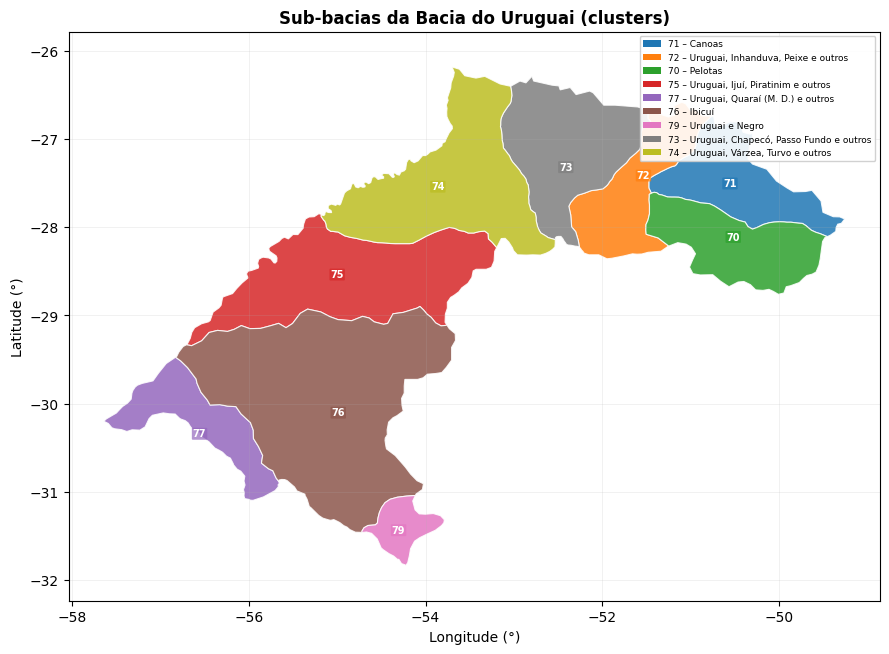

In [10]:
# --- Visualização dos clusters sobre o mapa ---

def get_patches(shape, **kwargs):
    """Converte shape (multi-part) em lista de patches matplotlib."""
    patches = []
    parts = list(shape.parts) + [len(shape.points)]
    for i in range(len(shape.parts)):
        pts = np.array(shape.points[parts[i]:parts[i+1]])
        if len(pts) >= 3:
            patches.append(MplPolygon(pts, closed=True, **kwargs))
    return patches

def get_centroid(shape):
    pts = np.array(shape.points)
    return pts[:, 0].mean(), pts[:, 1].mean()


fig, ax = plt.subplots(figsize=(9, 8))

for i, c in enumerate(clusters):
    color = CLUSTER_CMAP(i)
    for patch in get_patches(c['shape']):
        patch.set_facecolor(color)
        patch.set_edgecolor('white')
        patch.set_linewidth(0.8)
        patch.set_alpha(0.85)
        ax.add_patch(patch)
    cx, cy = get_centroid(c['shape'])
    ax.text(cx, cy, str(c['sub_id']), ha='center', va='center',
            fontsize=7, fontweight='bold', color='white',
            bbox=dict(boxstyle='round,pad=0.1', facecolor=color, edgecolor='none', alpha=0.7))

# Bbox da união dos clusters
all_pts = np.array([pt for c in clusters for pt in c['shape'].points])
margin = 0.4
ax.set_xlim(all_pts[:,0].min()-margin, all_pts[:,0].max()+margin)
ax.set_ylim(all_pts[:,1].min()-margin, all_pts[:,1].max()+margin)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3, linewidth=0.4)
ax.set_xlabel('Longitude (°)', fontsize=10)
ax.set_ylabel('Latitude (°)', fontsize=10)
ax.set_title('Sub-bacias da Bacia do Uruguai (clusters)', fontsize=12, fontweight='bold')

# Legenda
handles = [mpatches.Patch(facecolor=CLUSTER_CMAP(i), label=f"{c['sub_id']} – {c['name']}")
           for i, c in enumerate(clusters)]
ax.legend(handles=handles, loc='upper right', fontsize=6.5, framealpha=0.9)

plt.tight_layout()
plt.show()

---
## Passo 2 — Carregar a precipitação Xavier mensal

Os dados já estão processados em `data/processed/xavier_monthly/` com resolução de 0.1° e 708 meses (1961–2019). Cada ponto já representa a **precipitação acumulada mensal** (mm/mês).

In [11]:
# Bbox da união dos clusters + margem para recorte
lon_min = all_pts[:,0].min() - 0.5
lon_max = all_pts[:,0].max() + 0.5
lat_min = all_pts[:,1].min() - 0.5
lat_max = all_pts[:,1].max() + 0.5

ds = xr.open_dataset(XAVIER_NC)
ds_crop = ds.sel(
    latitude=slice(lat_min, lat_max),
    longitude=slice(lon_min, lon_max),
)

pr_arr    = ds_crop.pr.values          # shape: (n_time, n_lat, n_lon)
time_idx  = pd.DatetimeIndex(ds_crop.time.values)
lats_grid = ds_crop.latitude.values
lons_grid = ds_crop.longitude.values
n_time, n_lat, n_lon = pr_arr.shape
grid_shape = (n_lat, n_lon)

# Malha de coordenadas (para point-in-polygon)
lons2d, lats2d = np.meshgrid(lons_grid, lats_grid)
lons_flat = lons2d.ravel()
lats_flat = lats2d.ravel()

ds.close()

print('Dimensões após recorte:')
print(f'  pr_arr:  {pr_arr.shape}  (meses × lat × lon)')
print(f'  Período: {time_idx[0].date()} → {time_idx[-1].date()}  ({n_time} meses)')
print(f'  Lat:     {lat_min:.1f}° a {lat_max:.1f}°  ({n_lat} pontos)')
print(f'  Lon:     {lon_min:.1f}° a {lon_max:.1f}°  ({n_lon} pontos)')
print(f'  Total pontos de grade no recorte: {n_lat * n_lon:,}')

Dimensões após recorte:
  pr_arr:  (708, 66, 93)  (meses × lat × lon)
  Período: 1961-01-31 → 2019-12-31  (708 meses)
  Lat:     -32.3° a -25.7°  (66 pontos)
  Lon:     -58.1° a -48.8°  (93 pontos)
  Total pontos de grade no recorte: 6,138


---
## Passo 3 — Point-in-Polygon: quais pontos pertencem a cada cluster?

Para cada sub-bacia, verificamos quais pontos da grade de 0.1° caem **dentro** do polígono usando `matplotlib.path.Path.contains_points`. O resultado é uma máscara booleana 2D (n_lat × n_lon).

In [12]:
def get_cluster_mask(shape, lons_flat, lats_flat, grid_shape):
    """
    Retorna máscara 2D (n_lat, n_lon) com True nos pontos de grade
    que estão dentro do polígono. Suporta multi-part polygons.
    """
    grid_pts = np.column_stack([lons_flat, lats_flat])
    mask = np.zeros(len(grid_pts), dtype=bool)
    parts = list(shape.parts) + [len(shape.points)]
    for i in range(len(shape.parts)):
        pts = np.array(shape.points[parts[i]:parts[i+1]])
        if len(pts) >= 3:
            mask |= MplPath(pts).contains_points(grid_pts)
    return mask.reshape(grid_shape)


# Calcular máscara para cada cluster
masks = {}
print(f"{'Sub':>4}  {'Pontos':>7}  Nome")
print('-' * 65)
for c in clusters:
    mask2d = get_cluster_mask(c['shape'], lons_flat, lats_flat, grid_shape)
    masks[c['name']] = mask2d
    n_pts = mask2d.sum()
    print(f"{c['sub_id']:4d}  {n_pts:7d}  {c['name']}")
print(f"{'':>4}  {sum(m.sum() for m in masks.values()):7d}  TOTAL")

 Sub   Pontos  Nome
-----------------------------------------------------------------
  71      126  Canoas
  72      116  Uruguai, Inhanduva, Peixe e outros
  70      130  Pelotas
  75      250  Uruguai, Ijuí, Piratinim e outros
  77       95  Uruguai, Quaraí (M. D.) e outros
  76      450  Ibicuí
  79       34  Uruguai e Negro
  73      174  Uruguai, Chapecó, Passo Fundo e outros
  74      249  Uruguai, Várzea, Turvo e outros
         1624  TOTAL


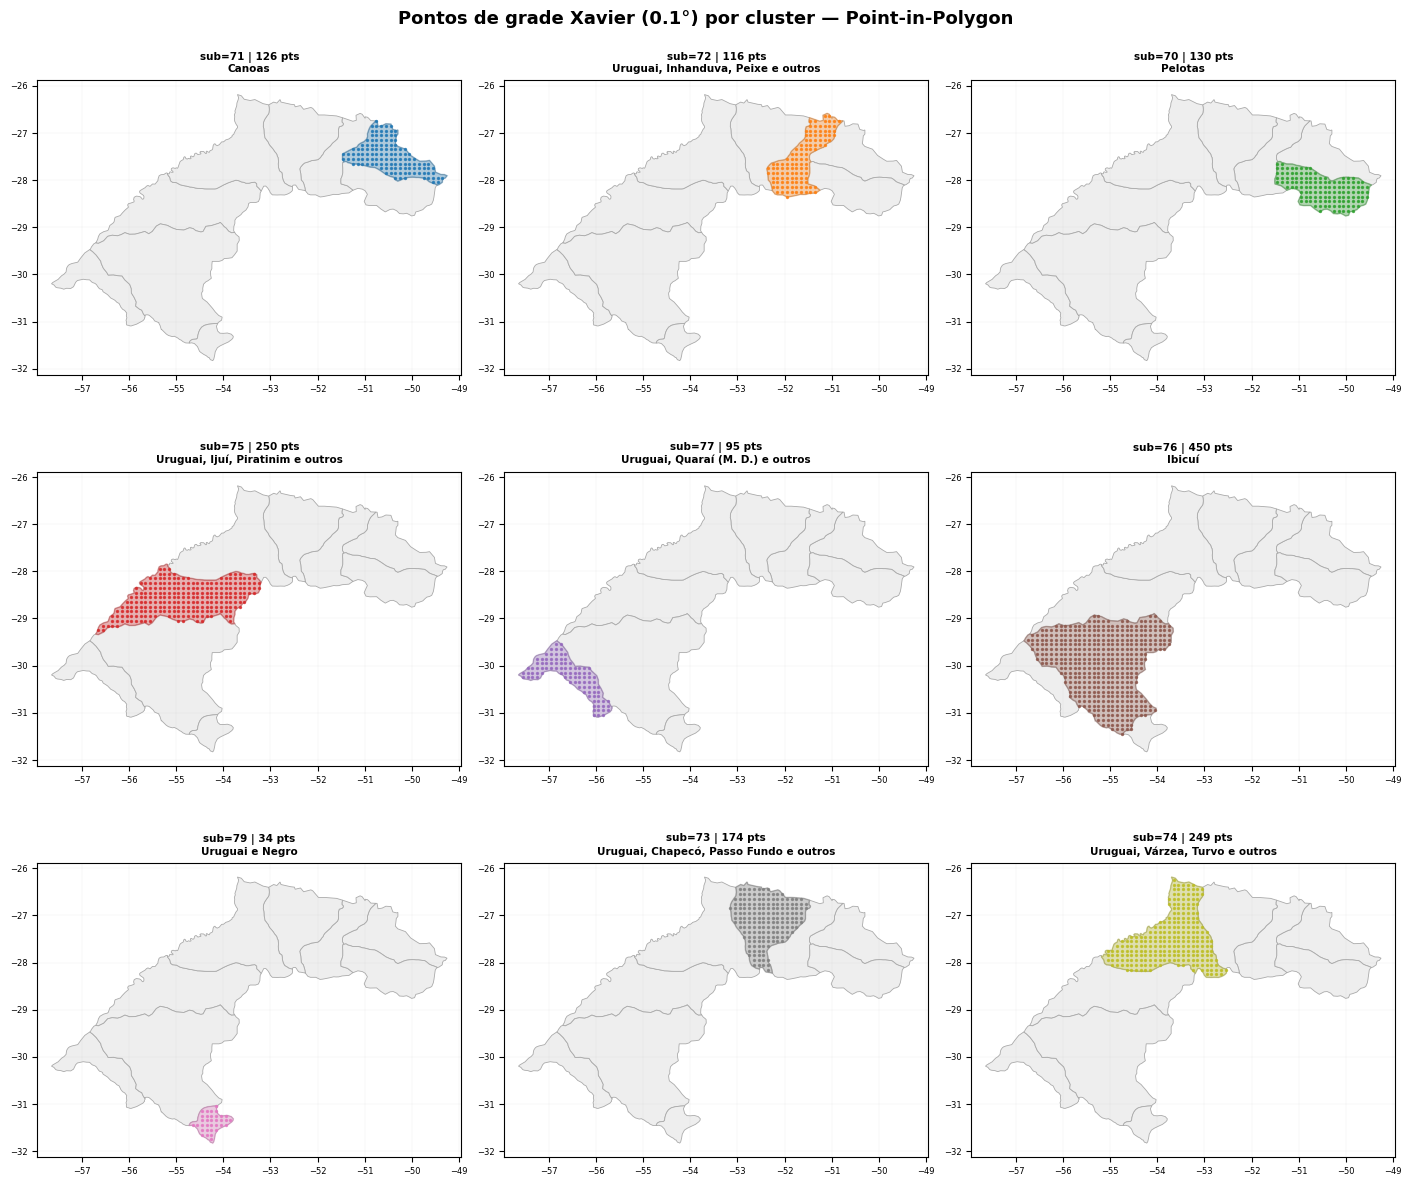

In [13]:
# --- Visualização: pontos de grade coloridos por cluster ---

fig, axes = plt.subplots(3, 3, figsize=(14, 12), constrained_layout=True)
axes = axes.ravel()

for i, c in enumerate(clusters):
    ax = axes[i]
    color = CLUSTER_CMAP(i)
    mask2d = masks[c['name']]

    # Plotar borda de todos os clusters em cinza
    for c2 in clusters:
        for patch in get_patches(c2['shape']):
            patch.set_facecolor('#eeeeee')
            patch.set_edgecolor('#aaaaaa')
            patch.set_linewidth(0.6)
            ax.add_patch(patch)

    # Destacar o cluster atual
    for patch in get_patches(c['shape']):
        patch.set_facecolor(color)
        patch.set_alpha(0.3)
        patch.set_edgecolor(color)
        patch.set_linewidth(1.2)
        ax.add_patch(patch)

    # Pontos de grade selecionados
    sel_lons = lons_flat[mask2d.ravel()]
    sel_lats = lats_flat[mask2d.ravel()]
    ax.scatter(sel_lons, sel_lats, s=2, color=color, zorder=3, alpha=0.8)

    ax.set_xlim(all_pts[:,0].min()-0.3, all_pts[:,0].max()+0.3)
    ax.set_ylim(all_pts[:,1].min()-0.3, all_pts[:,1].max()+0.3)
    ax.set_aspect('equal')
    ax.set_title(f"sub={c['sub_id']} | {mask2d.sum()} pts\n{c['name']}",
                 fontsize=7.5, fontweight='bold')
    ax.tick_params(labelsize=6)
    ax.grid(True, alpha=0.2, linewidth=0.3)

fig.suptitle('Pontos de grade Xavier (0.1°) por cluster — Point-in-Polygon',
             fontsize=13, fontweight='bold')
plt.show()

---
## Passo 4 — Acumulado espacial mensal por cluster

Para cada mês, **somamos** a precipitação de todos os pontos do cluster.

**Por que soma e não média?**  
Cada ponto já representa a precipitação acumulada mensal (mm/mês) naquele ponto de 0.1°. A soma espacial representa o **volume total de precipitação** que cai sobre o cluster. É a operação correta para representar o acumulado de uma bacia hidrográfica.

In [14]:
# Acumulado espacial mensal: uma série temporal por cluster

pr_flat = pr_arr.reshape(n_time, -1)  # (n_time, n_lat*n_lon)

cluster_series = {}  # nome → array (n_time,)

for c in clusters:
    mask_flat = masks[c['name']].ravel()
    # Selecionar apenas os pontos do cluster: shape (n_time, n_pts_cluster)
    pr_cluster_pts = pr_flat[:, mask_flat]
    # Soma espacial → (n_time,)
    pr_cluster_sum = pr_cluster_pts.sum(axis=1)
    cluster_series[c['name']] = pr_cluster_sum

# Visualização: passo a passo para um cluster
example_name = clusters[0]['name']  # Canoas
example_series = cluster_series[example_name]
example_mask   = masks[example_name].ravel()
n_pts_example  = example_mask.sum()

print(f'Exemplo: "{example_name}"')
print(f'  Pontos de grade selecionados: {n_pts_example}')
print(f'  Shape dos dados do cluster:   (n_time={n_time}, n_pts={n_pts_example})')
print(f'  Após soma espacial:           (n_time={n_time},)')
print(f'  Valores (primeiros 6 meses):')
for k in range(6):
    print(f'    {time_idx[k].strftime("%Y-%m")}: {example_series[k]:,.1f} mm (soma de {n_pts_example} pontos)')

Exemplo: "Canoas"
  Pontos de grade selecionados: 126
  Shape dos dados do cluster:   (n_time=708, n_pts=126)
  Após soma espacial:           (n_time=708,)
  Valores (primeiros 6 meses):
    1961-01: 19,039.6 mm (soma de 126 pontos)
    1961-02: 20,246.1 mm (soma de 126 pontos)
    1961-03: 24,977.7 mm (soma de 126 pontos)
    1961-04: 13,563.5 mm (soma de 126 pontos)
    1961-05: 7,912.6 mm (soma de 126 pontos)
    1961-06: 10,342.7 mm (soma de 126 pontos)


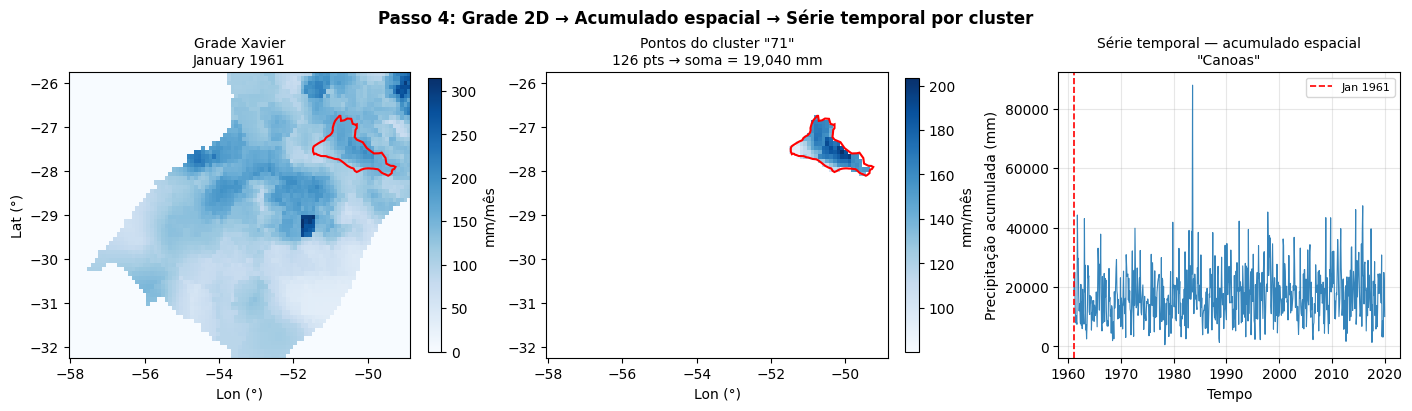

In [15]:
# --- Diagrama conceitual: de grade 2D para série 1D ---

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

# Painel 1: mapa de precipitação de um mês
ax = axes[0]
month_idx = 0  # Janeiro 1961
pr_month = pr_arr[month_idx]  # (n_lat, n_lon)
im = ax.imshow(pr_month, origin='lower', cmap='Blues',
               extent=[lons_grid[0], lons_grid[-1], lats_grid[0], lats_grid[-1]],
               aspect='auto')
# Contorno do cluster exemplo
for patch in get_patches(clusters[0]['shape']):
    patch.set_facecolor('none')
    patch.set_edgecolor('red')
    patch.set_linewidth(1.5)
    ax.add_patch(patch)
plt.colorbar(im, ax=ax, label='mm/mês', fraction=0.04)
ax.set_title(f'Grade Xavier\n{time_idx[month_idx].strftime("%B %Y")}', fontsize=10)
ax.set_xlabel('Lon (°)')
ax.set_ylabel('Lat (°)')
ax.set_xlim(lons_grid[0], lons_grid[-1])
ax.set_ylim(lats_grid[0], lats_grid[-1])

# Painel 2: apenas os pontos do cluster
ax = axes[1]
pr_month_masked = np.where(masks[example_name], pr_month, np.nan)
im2 = ax.imshow(pr_month_masked, origin='lower', cmap='Blues',
                extent=[lons_grid[0], lons_grid[-1], lats_grid[0], lats_grid[-1]],
                aspect='auto')
for patch in get_patches(clusters[0]['shape']):
    patch.set_facecolor('none')
    patch.set_edgecolor('red')
    patch.set_linewidth(1.5)
    ax.add_patch(patch)
plt.colorbar(im2, ax=ax, label='mm/mês', fraction=0.04)
n_pts_ex = masks[example_name].sum()
soma = example_series[month_idx]
ax.set_title(f'Pontos do cluster "{clusters[0]["sub_id"]}"\n'
             f'{n_pts_ex} pts → soma = {soma:,.0f} mm', fontsize=10)
ax.set_xlabel('Lon (°)')
ax.set_xlim(lons_grid[0], lons_grid[-1])
ax.set_ylim(lats_grid[0], lats_grid[-1])

# Painel 3: série temporal resultante
ax = axes[2]
ax.plot(time_idx, example_series, color=CLUSTER_CMAP(0), linewidth=0.8, alpha=0.9)
ax.axvline(time_idx[month_idx], color='red', linewidth=1.2, linestyle='--', label=time_idx[month_idx].strftime('%b %Y'))
ax.set_title(f'Série temporal — acumulado espacial\n"{clusters[0]["name"]}"', fontsize=10)
ax.set_xlabel('Tempo')
ax.set_ylabel('Precipitação acumulada (mm)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

fig.suptitle('Passo 4: Grade 2D → Acumulado espacial → Série temporal por cluster',
             fontsize=12, fontweight='bold')
plt.show()

---
## Passo 5 — Climatologia mensal de cada cluster

Com a série mensal pronta, calculamos a **climatologia**: a média de cada mês do ano ao longo de toda a série histórica (1961–2019).

- Climatologia de Janeiro = média de todos os Janeiros (1961, 1962, ..., 2019)
- Climatologia de Fevereiro = média de todos os Fevereiros
- ... e assim por diante para os 12 meses.

In [16]:
months_idx = time_idx.month  # array com o mês de cada timestep

cluster_clim = {}   # nome → array (12,)  — climatologia mensal

for c in clusters:
    serie = cluster_series[c['name']]
    clim = np.array([
        serie[months_idx == m].mean()
        for m in range(1, 13)
    ])  # shape (12,)
    cluster_clim[c['name']] = clim

# Tabela de climatologia
month_names = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
df_clim = pd.DataFrame(
    {c['name'].split(',')[0]: cluster_clim[c['name']] for c in clusters},
    index=month_names
)
print('Climatologia mensal por cluster (mm acumulados):')
print(df_clim.to_string(float_format='{:,.0f}'.format))

Climatologia mensal por cluster (mm acumulados):
     Canoas  Uruguai  Pelotas  Ibicuí  Uruguai e Negro
Jan  21,236   39,989   20,908  62,385            4,023
Fev  20,121   36,195   20,191  59,522            4,069
Mar  15,625   32,712   16,359  61,676            3,855
Abr  13,254   36,066   13,925  66,550            4,327
Mai  14,881   36,308   15,643  57,004            3,814
Jun  14,697   34,427   15,706  51,452            3,825
Jul  15,647   32,198   17,969  54,084            4,355
Ago  15,251   30,979   17,320  45,715            3,814
Set  19,771   38,508   21,263  62,873            4,558
Out  21,775   50,197   22,005  75,511            4,848
Nov  16,599   37,139   17,153  60,196            3,700
Dez  18,290   39,417   18,391  57,500            3,668


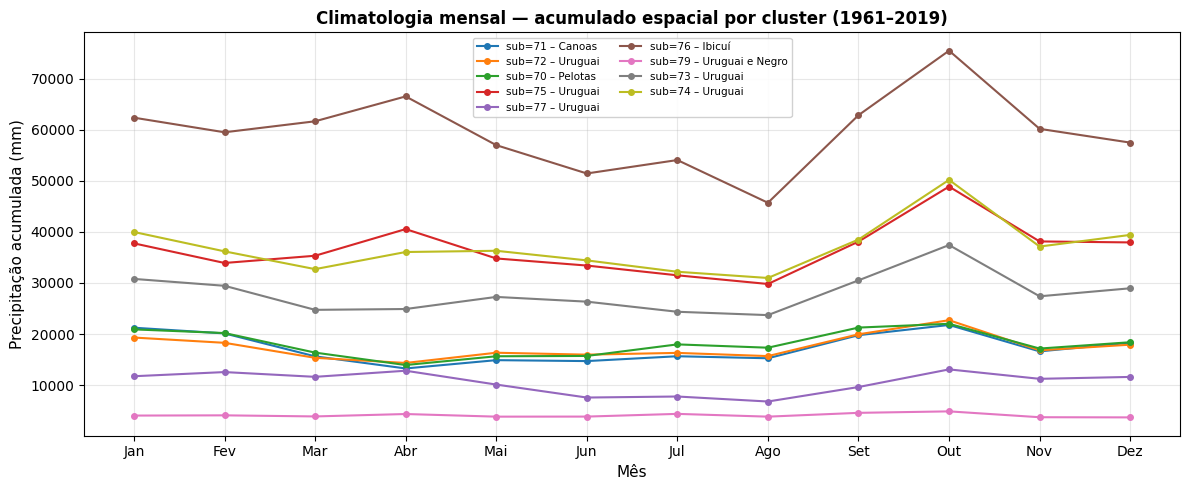

In [17]:
# --- Visualização: climatologia mensal de todos os clusters ---

fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(1, 13)
for i, c in enumerate(clusters):
    clim = cluster_clim[c['name']]
    label = f"sub={c['sub_id']} – {c['name'].split(',')[0]}"
    ax.plot(x, clim, marker='o', markersize=4, linewidth=1.5,
            color=CLUSTER_CMAP(i), label=label)

ax.set_xticks(x)
ax.set_xticklabels(month_names)
ax.set_xlabel('Mês', fontsize=11)
ax.set_ylabel('Precipitação acumulada (mm)', fontsize=11)
ax.set_title('Climatologia mensal — acumulado espacial por cluster (1961–2019)', fontsize=12, fontweight='bold')
ax.legend(fontsize=7.5, ncol=2, framealpha=0.9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Passo 6 — Anomalia mensal de cada cluster

**Anomalia = acumulado mensal do cluster − climatologia do mês correspondente**

Por exemplo, para Janeiro de 1983:  
`anomalia(Jan/1983) = pr_cluster(Jan/1983) − climatologia(Jan)`

A série de anomalias resultante tem média ≈ 0 por construção.

In [18]:
cluster_anomaly = {}  # nome → array (n_time,)

for c in clusters:
    serie = cluster_series[c['name']]
    clim  = cluster_clim[c['name']]
    # Subtrair climatologia do mês correspondente
    anomaly = serie - clim[months_idx - 1]   # months_idx-1 converte 1-12 → 0-11
    cluster_anomaly[c['name']] = anomaly

# Verificação: a média das anomalias deve ser ≈ 0
print('Verificação — média das anomalias por cluster (deve ser ≈ 0):')
for c in clusters:
    mean_anom = cluster_anomaly[c['name']].mean()
    print(f"  sub={c['sub_id']:3d}  {c['name']:<45}  média={mean_anom:+.6f}")

Verificação — média das anomalias por cluster (deve ser ≈ 0):
  sub= 71  Canoas                                         média=+0.000000
  sub= 72  Uruguai, Inhanduva, Peixe e outros             média=-0.000000
  sub= 70  Pelotas                                        média=+0.000000
  sub= 75  Uruguai, Ijuí, Piratinim e outros              média=+0.000000
  sub= 77  Uruguai, Quaraí (M. D.) e outros               média=-0.000000
  sub= 76  Ibicuí                                         média=-0.000000
  sub= 79  Uruguai e Negro                                média=+0.000000
  sub= 73  Uruguai, Chapecó, Passo Fundo e outros         média=+0.000000
  sub= 74  Uruguai, Várzea, Turvo e outros                média=-0.000000


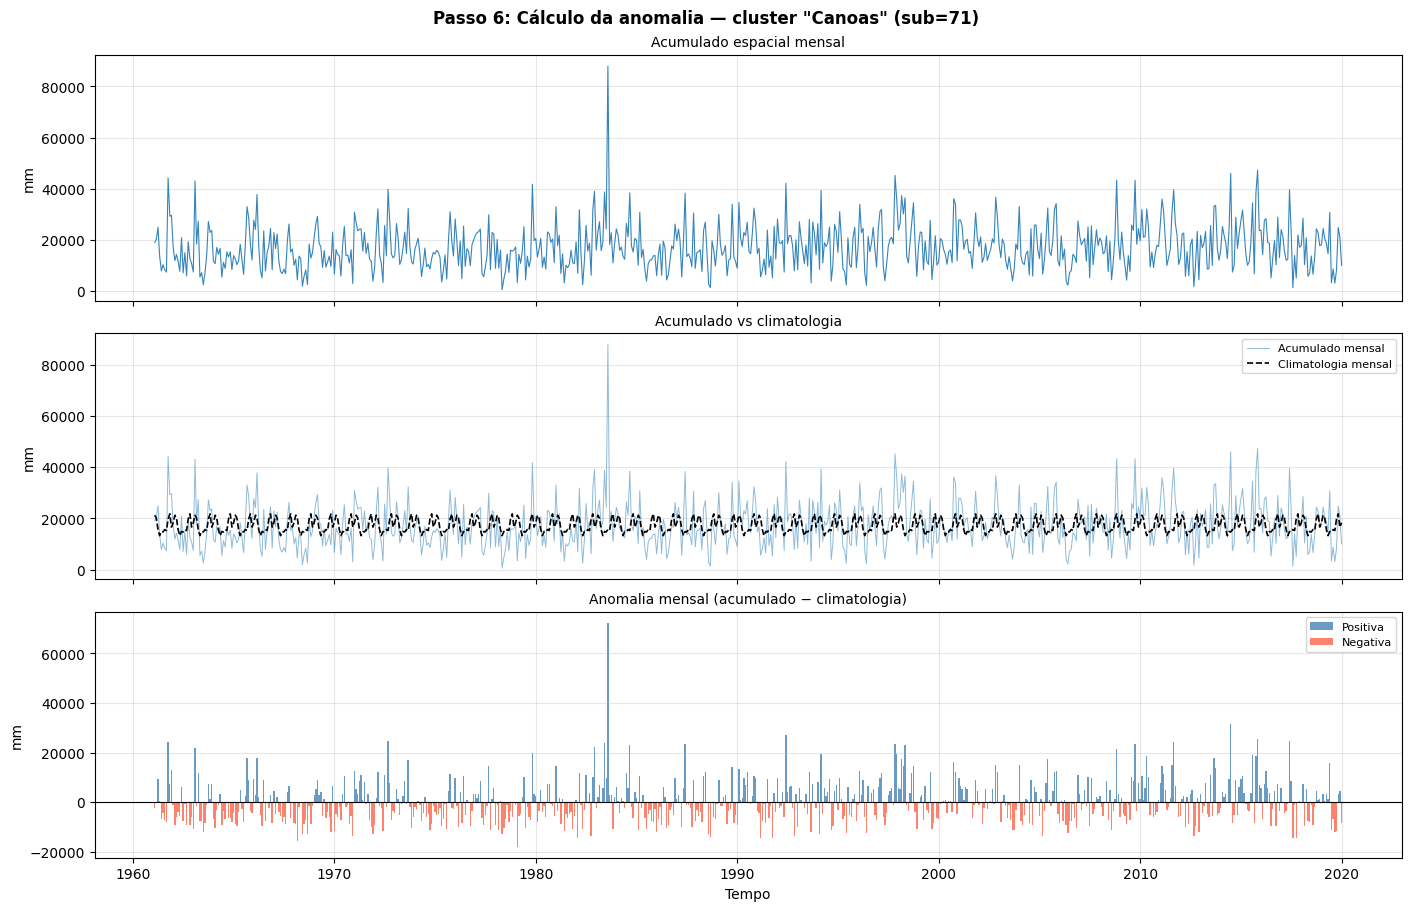

In [19]:
# --- Visualização: série original, climatologia e anomalia para um cluster ---

c = clusters[0]  # Canoas
serie   = cluster_series[c['name']]
clim    = cluster_clim[c['name']]
anomaly = cluster_anomaly[c['name']]
color   = CLUSTER_CMAP(0)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, constrained_layout=True)

# Série original
axes[0].plot(time_idx, serie, color=color, linewidth=0.8, alpha=0.9)
axes[0].set_ylabel('mm', fontsize=10)
axes[0].set_title('Acumulado espacial mensal', fontsize=10)
axes[0].grid(True, alpha=0.3)

# Climatologia repetida sobre a série
clim_repeated = clim[months_idx - 1]
axes[1].plot(time_idx, serie, color=color, linewidth=0.7, alpha=0.5, label='Acumulado mensal')
axes[1].plot(time_idx, clim_repeated, color='black', linewidth=1.2,
             linestyle='--', label='Climatologia mensal')
axes[1].set_ylabel('mm', fontsize=10)
axes[1].set_title('Acumulado vs climatologia', fontsize=10)
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

# Anomalia
pos = anomaly >= 0
axes[2].bar(time_idx[pos],  anomaly[pos],  color='steelblue', width=25, alpha=0.8, label='Positiva')
axes[2].bar(time_idx[~pos], anomaly[~pos], color='tomato',    width=25, alpha=0.8, label='Negativa')
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_ylabel('mm', fontsize=10)
axes[2].set_xlabel('Tempo', fontsize=10)
axes[2].set_title('Anomalia mensal (acumulado − climatologia)', fontsize=10)
axes[2].legend(fontsize=8)
axes[2].grid(True, alpha=0.3)

fig.suptitle(f'Passo 6: Cálculo da anomalia — cluster "{c["name"]}" (sub={c["sub_id"]})',
             fontsize=12, fontweight='bold')
plt.show()

---
## Passo 7 — Visão geral: anomalias de todos os clusters

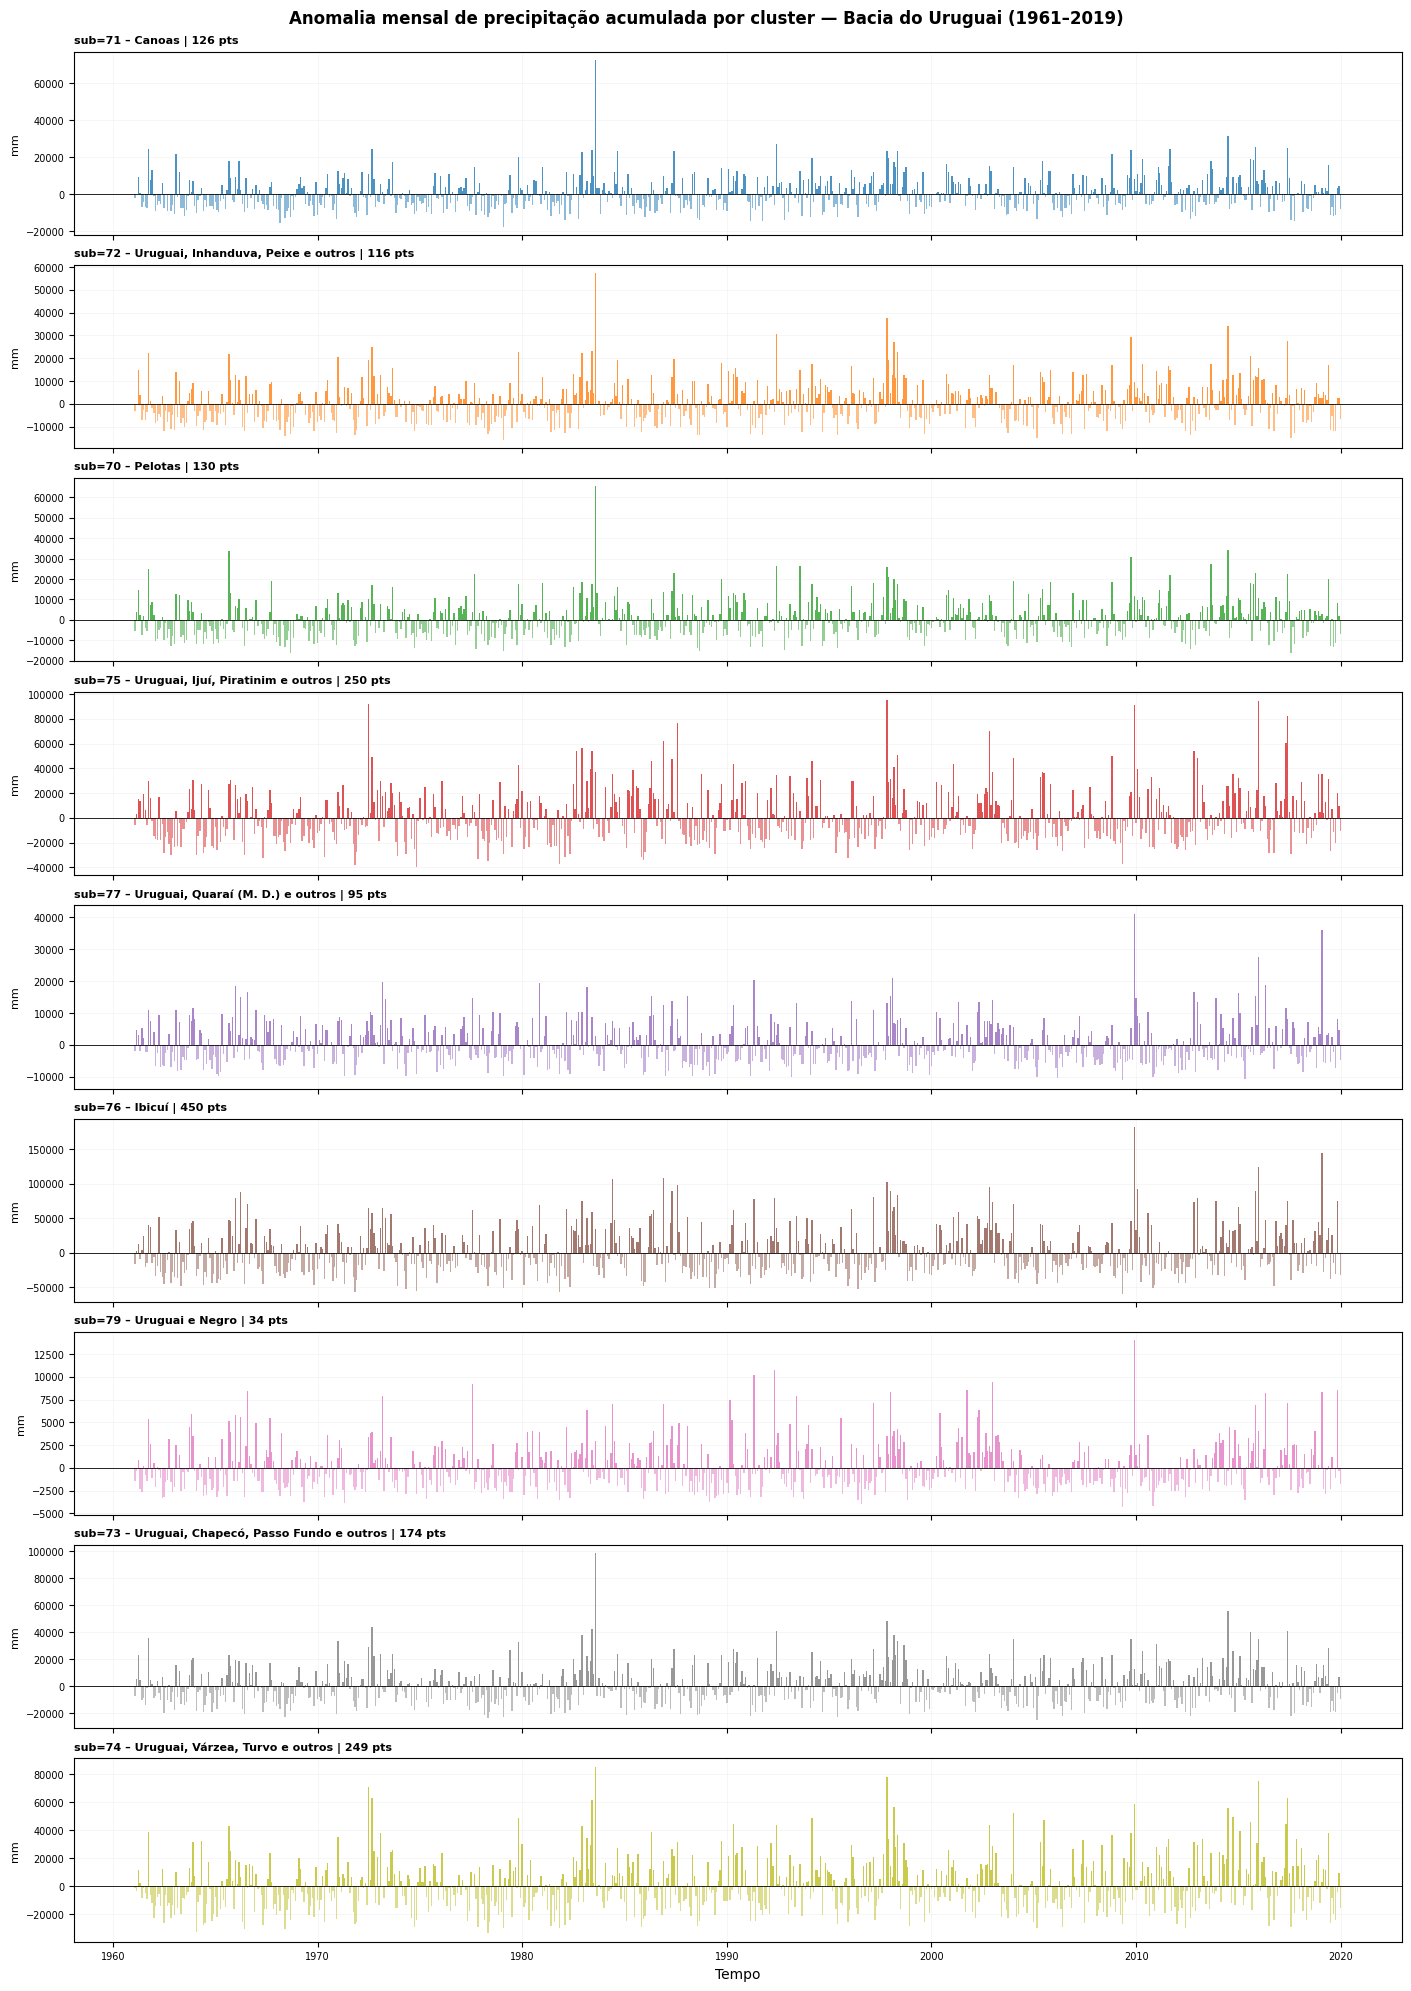

In [20]:
fig, axes = plt.subplots(len(clusters), 1, figsize=(14, 2.2 * len(clusters)),
                         sharex=True, constrained_layout=True)

for i, c in enumerate(clusters):
    ax = axes[i]
    anomaly = cluster_anomaly[c['name']]
    color = CLUSTER_CMAP(i)
    pos = anomaly >= 0
    ax.bar(time_idx[pos],  anomaly[pos],  color=color,  width=25, alpha=0.8)
    ax.bar(time_idx[~pos], anomaly[~pos], color=color,  width=25, alpha=0.5)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_ylabel('mm', fontsize=8)
    ax.set_title(f"sub={c['sub_id']} – {c['name']} | {masks[c['name']].sum()} pts",
                 fontsize=8, fontweight='bold', loc='left')
    ax.grid(True, alpha=0.2, linewidth=0.4)
    ax.tick_params(labelsize=7)

axes[-1].set_xlabel('Tempo', fontsize=10)
fig.suptitle('Anomalia mensal de precipitação acumulada por cluster — Bacia do Uruguai (1961–2019)',
             fontsize=12, fontweight='bold')
plt.show()

---
## Resumo do pipeline

```
Xavier mensal (0.1°, 708 meses)
    ↓ recorte na bbox do Uruguai
Grade 2D (66 lat × 93 lon = 6.138 pontos)
    ↓ point-in-polygon por sub-bacia
Pontos do cluster (126–450 pts por cluster)
    ↓ soma espacial (por mês)
Série mensal acumulada do cluster  → shape (708,)
    ↓ média por mês do ano
Climatologia mensal do cluster     → shape (12,)
    ↓ subtração
Anomalia mensal do cluster         → shape (708,)  com média ≈ 0
    ↓ PREDEP(anomalia, MoV, lag)
Alpha por (cluster, MoV, lag)      → 1053 valores
```

O script completo do pipeline está em `experiments/04_predep_uruguai_clusters.py`  
e os resultados em `results/predep_uruguai_clusters/predep_results.csv`.